# Experiment No.6- Decision Tree

# Cell 1: Import libraries

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Cell 2: Load the dataset

In [12]:
df = pd.read_csv("data.csv")

# Remove unnecessary columns
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully
Dataset shape: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# Cell 3: Check missing values

In [13]:
print("Missing values:")
print(df.isnull().sum().sum())

print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())

Missing values:
0

Diagnosis distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64


# Cell 4: Separate input and target

In [14]:
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (569, 30)
Target shape: (569,)


# Cell 5: Split the dataset

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


# Cell 6: Train the Decision Tree model

In [16]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully")

Decision Tree model trained successfully


# Cell 7: Make predictions

In [17]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Diagnosis": y_test,
    "Predicted Diagnosis": y_pred
})

display(results.head(10))

,Actual Diagnosis,Predicted Diagnosis
120,B,B
250,M,M
375,B,M
99,M,B
455,B,B
318,B,B
39,M,M
371,B,B
98,B,B
502,B,B


# Cell 8: Calculate accuracy

In [18]:
accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Decision Tree Accuracy: 91.23 %

Classification Report:
              precision    recall  f1-score   support

           B       0.90      0.97      0.93        72
           M       0.94      0.81      0.87        42

    accuracy                           0.91       114
   macro avg       0.92      0.89      0.90       114
weighted avg       0.91      0.91      0.91       114

Confusion Matrix:
[[70  2]
 [ 8 34]]


# Cell 9: Visualize the Decision Tree

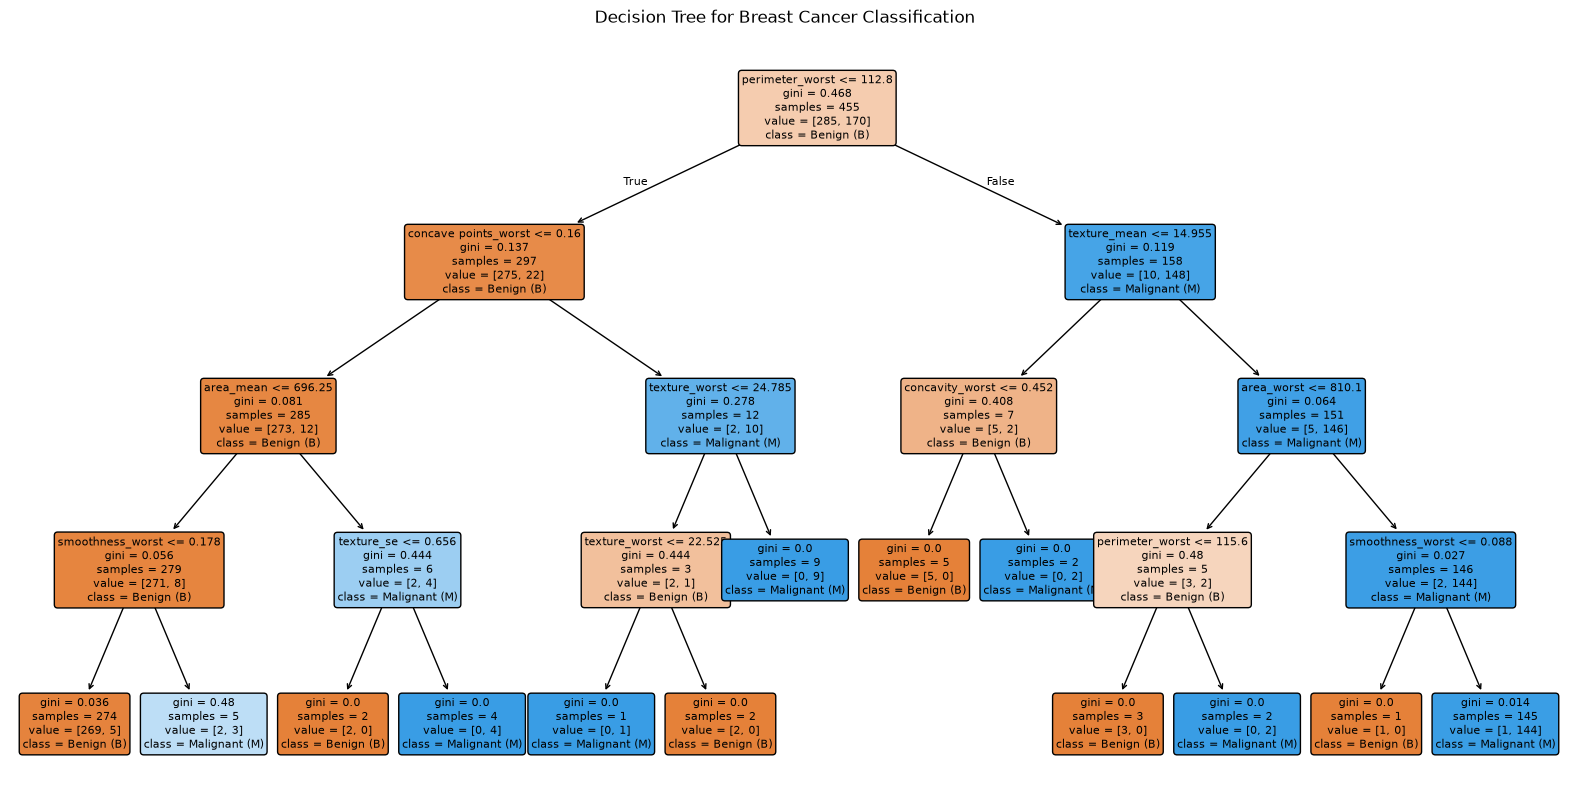

In [19]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Benign (B)", "Malignant (M)"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Breast Cancer Classification")
plt.show()

# Cell 10: Predict a diagnosis

In [20]:
new_data = X_test.iloc[[0]]

prediction = model.predict(new_data)[0]

print("Predicted Diagnosis:", prediction)

if prediction == "M":
    print("Result: Malignant")
else:
    print("Result: Benign")

Predicted Diagnosis: B
Result: Benign
